# PCD_Assignment02
## Image Enhancement on a Blurred Image Using Unsharp Masking

This notebook implements image enhancement for a blurred image.

### Experiment flow
1. Load the original image.
2. Create a degraded image using Gaussian Blur.
3. Enhance the blurred image using Unsharp Masking.
4. Compare the original, blurred, and enhanced images.
5. Evaluate the results using MSE and PSNR.
6. Save all output images.

The main image used in this experiment is a basketball court photograph.


In [6]:
# Import required libraries
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image


## 1. Load the Original Image

The original image is used as the reference image.  
If the `images/original.jpg` file is not found, the notebook will ask you to upload it manually in Google Colab.


Image shape: (1600, 900, 3)


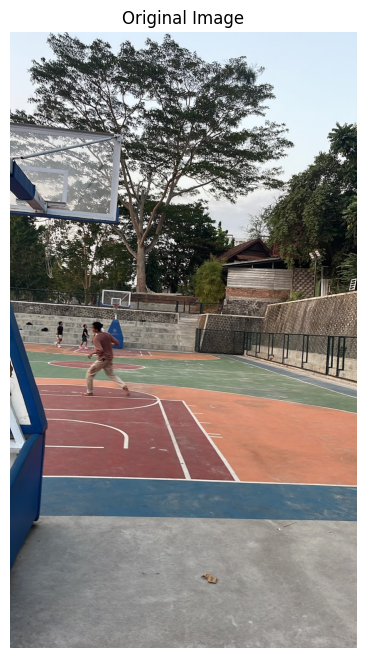

In [7]:
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

image_path = IMAGE_DIR / "original.jpg"

if not image_path.exists():
    try:
        from google.colab import files
        print("images/original.jpg was not found. Please upload the original basketball image.")
        uploaded = files.upload()
        uploaded_name = next(iter(uploaded))
        with open(image_path, "wb") as f:
            f.write(uploaded[uploaded_name])
    except ImportError:
        raise FileNotFoundError("Place the original image at images/original.jpg")

original_bgr = cv2.imread(str(image_path))

if original_bgr is None:
    raise ValueError("The image could not be loaded.")

original = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

print("Image shape:", original.shape)

plt.figure(figsize=(6, 8))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()


## 2. Create a Blurred Image

Gaussian Blur is applied to simulate image degradation.  
A blurred image loses fine details and edge sharpness, making it suitable for an image enhancement experiment.


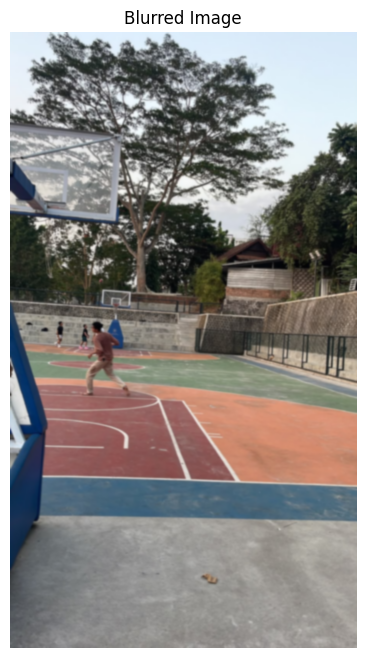

In [8]:
blurred = cv2.GaussianBlur(
    original,
    (0, 0),
    sigmaX=2.0,
    sigmaY=2.0
)

plt.figure(figsize=(6, 8))
plt.imshow(blurred)
plt.title("Blurred Image")
plt.axis("off")
plt.show()


## 3. Enhance the Blurred Image Using Unsharp Masking

Unsharp Masking enhances edge information by subtracting a smoother version of the image from the blurred image and adding the extracted detail back.

In this experiment:
- the blurred image is smoothed again,
- the difference represents high-frequency detail,
- the detail is added back with a sharpening amount of 2.5.


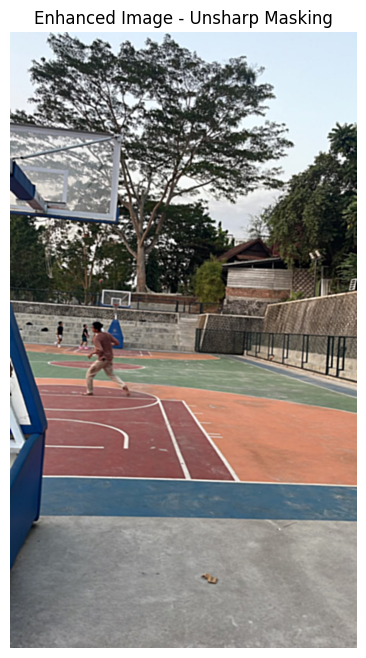

In [9]:
smooth = cv2.GaussianBlur(
    blurred,
    (0, 0),
    sigmaX=2.0,
    sigmaY=2.0
)

amount = 2.5

# Equivalent to: blurred + amount * (blurred - smooth)
enhanced = cv2.addWeighted(
    blurred, 1 + amount,
    smooth, -amount,
    0
)

plt.figure(figsize=(6, 8))
plt.imshow(enhanced)
plt.title("Enhanced Image - Unsharp Masking")
plt.axis("off")
plt.show()


## 4. Visual Comparison

The three images are displayed side by side to compare the changes caused by blurring and sharpening.


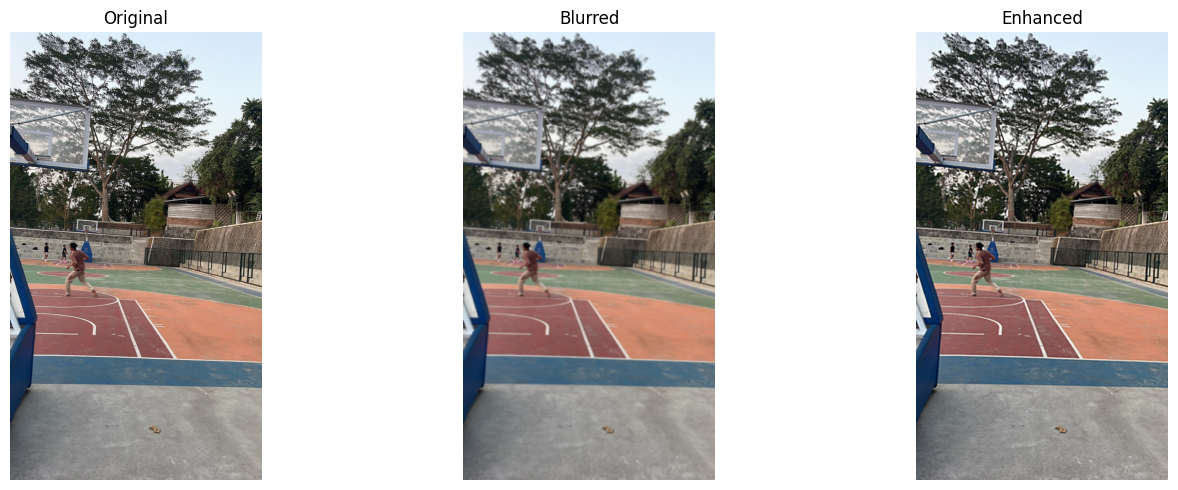

In [10]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred)
plt.title("Blurred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(enhanced)
plt.title("Enhanced")
plt.axis("off")

plt.tight_layout()
plt.show()


## 5. Quantitative Evaluation

Two metrics are used:

### Mean Squared Error (MSE)
MSE measures the average squared difference between the processed image and the original image.  
A lower MSE indicates that the processed image is closer to the original.

### Peak Signal-to-Noise Ratio (PSNR)
PSNR measures reconstruction quality relative to the reference image.  
A higher PSNR generally indicates better similarity to the original image.


In [11]:
def calculate_mse(reference, test):
    reference = reference.astype(np.float32)
    test = test.astype(np.float32)
    return np.mean((reference - test) ** 2)

def calculate_psnr(reference, test):
    mse_value = calculate_mse(reference, test)

    if mse_value == 0:
        return float("inf")

    return 20 * np.log10(255.0 / np.sqrt(mse_value))

mse_blurred = calculate_mse(original, blurred)
mse_enhanced = calculate_mse(original, enhanced)

psnr_blurred = calculate_psnr(original, blurred)
psnr_enhanced = calculate_psnr(original, enhanced)

print("===== BLURRED IMAGE =====")
print(f"MSE  : {mse_blurred:.4f}")
print(f"PSNR : {psnr_blurred:.4f} dB")

print("\n===== ENHANCED IMAGE =====")
print(f"MSE  : {mse_enhanced:.4f}")
print(f"PSNR : {psnr_enhanced:.4f} dB")


===== BLURRED IMAGE =====
MSE  : 682.2217
PSNR : 19.7915 dB

===== ENHANCED IMAGE =====
MSE  : 502.6886
PSNR : 21.1178 dB


### Expected Result for the Provided Basketball Image

Using the parameters in this notebook, the provided image produces approximately:

| Image | MSE | PSNR |
|---|---:|---:|
| Blurred | 682.2215 | 19.7915 dB |
| Enhanced | 502.6888 | 21.1178 dB |

The enhanced image has a lower MSE and higher PSNR than the blurred image, which indicates that the enhancement moves the degraded image closer to the original reference.


## 6. Save the Result Images

The original, blurred, enhanced, and comparison images are saved inside the `images` folder so they can be uploaded to GitHub together with this notebook.


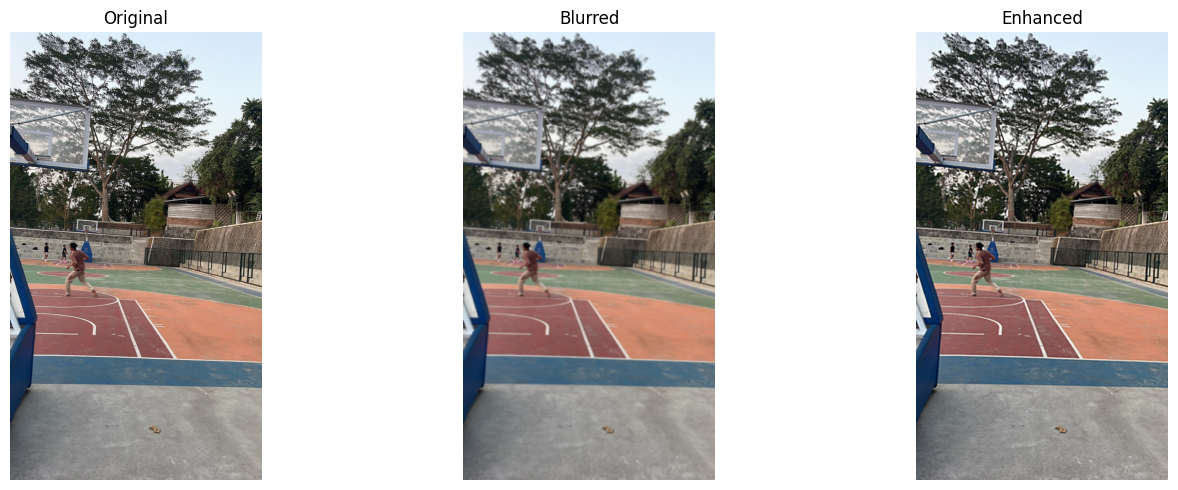

All output images were saved to the images folder.


In [12]:
Image.fromarray(original).save(IMAGE_DIR / "original.jpg")
Image.fromarray(blurred).save(IMAGE_DIR / "blurred.jpg")
Image.fromarray(enhanced).save(IMAGE_DIR / "enhanced.jpg")

plt.figure(figsize=(15, 5))

for i, (img, title) in enumerate([
    (original, "Original"),
    (blurred, "Blurred"),
    (enhanced, "Enhanced")
], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.savefig(IMAGE_DIR / "comparison.png", dpi=170, bbox_inches="tight")
plt.show()

print("All output images were saved to the images folder.")


## Conclusion

This experiment demonstrates image enhancement on a blurred image using Unsharp Masking.

Gaussian Blur was first applied to the original image to simulate degradation. The blurred image showed reduced edge sharpness and loss of fine details. Unsharp Masking was then applied to emphasize high-frequency information and improve the visibility of edges.

The enhanced image appears sharper than the blurred image. The quantitative evaluation also shows improvement: the enhanced image produces a lower MSE and a higher PSNR compared with the blurred image.

Therefore, Unsharp Masking can be used as a simple image enhancement technique for improving the visual sharpness of blurred images. However, sharpening does not perfectly recover all information lost during the blurring process, so visual inspection and quantitative metrics should both be considered when evaluating the result.
